
# Linear regression and Bayesian bootstrap pKa analysis

This notebook reads `pka_dft_experimental.xlsx` from the same directory as the notebook, fits a linear regression of experimental pKa values against DFT-calculated pKa values, estimates a 95% confidence band by Bayesian bootstrapping, and predicts experimental pKa values for compounds without experimental values.

Generated files:

- `pka_regression_calibration.png`: calibration compounds only
- `pka_regression_with_predictions.png`: calibration compounds plus predicted positions for compounds lacking experimental pKa values
- `pka_predictions.csv`: numerical prediction table


In [18]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility
RANDOM_SEED = 20260702
rng = np.random.default_rng(RANDOM_SEED)

# Input/output paths. The Excel file is assumed to be in the same directory as this notebook.
DATA_PATH = Path("pka_dft_experimental.xlsx")
PLOT_CALIBRATION_PATH = Path("pka_regression_calibration.png")
PLOT_WITH_PREDICTIONS_PATH = Path("pka_regression_with_predictions.png")
PREDICTIONS_CSV_PATH = Path("pka_predictions.csv")

# Bayesian bootstrap settings
N_BOOTSTRAP = 100_000
CI_LOW, CI_HIGH = 2.5, 97.5


In [19]:
# Load the workbook
excel_file = pd.ExcelFile(DATA_PATH)
sheet_name = excel_file.sheet_names[0]
df = pd.read_excel(DATA_PATH, sheet_name=sheet_name)

print(f"Loaded sheet: {sheet_name}")
display(df)


Loaded sheet: Tabelle1


,compound,pka_exp,pka_dft
0,A,7.51,14.184364
1,B,6.67,12.735620
2,C,6.79,13.051610
3,D,7.68,14.406895
4,E,7.16,13.569660
5,F,8.07,14.448094
6,G,8.82,15.528333
7,H,6.29,12.114742
8,I,5.89,11.097734
9,P7,2.55,6.740152


In [20]:

# Column names expected in the workbook.
# Change these only if the source file column names change.
COMPOUND_COL = "compound"
EXP_COL = "pka_exp"
DFT_COL = "pka_dft"

required_cols = {COMPOUND_COL, EXP_COL, DFT_COL}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    raise ValueError(f"Missing required column(s): {sorted(missing_cols)}")

# Keep only rows that contain a compound name and DFT pKa.
# Regression rows also need experimental pKa.
df = df[[COMPOUND_COL, EXP_COL, DFT_COL]].copy()
df[EXP_COL] = pd.to_numeric(df[EXP_COL], errors="coerce")
df[DFT_COL] = pd.to_numeric(df[DFT_COL], errors="coerce")
df = df.dropna(subset=[COMPOUND_COL, DFT_COL])

calibration_df = df.dropna(subset=[EXP_COL]).copy().reset_index(drop=True)
prediction_df = df[df[EXP_COL].isna()].copy().reset_index(drop=True)

if len(calibration_df) < 3:
    raise ValueError("At least 3 calibration compounds with experimental and DFT pKa values are recommended.")
if prediction_df.empty:
    print("No compounds with missing experimental pKa values were found.")

print(f"Calibration compounds: {len(calibration_df)}")
print(f"Prediction compounds: {len(prediction_df)}")

display(calibration_df)
display(prediction_df)


Calibration compounds: 10
Prediction compounds: 2


,compound,pka_exp,pka_dft
0,A,7.51,14.184364
1,B,6.67,12.735620
2,C,6.79,13.051610
3,D,7.68,14.406895
4,E,7.16,13.569660
5,F,8.07,14.448094
6,G,8.82,15.528333
7,H,6.29,12.114742
8,I,5.89,11.097734
9,P7,2.55,6.740152


,compound,pka_exp,pka_dft
0,P8,NaN,6.934863
1,P9,NaN,7.735269


In [21]:
def fit_linear_regression(x, y):
    """Return slope, intercept, fitted y values, and R^2 for y = slope*x + intercept."""
    slope, intercept = np.polyfit(x, y, deg=1)
    y_hat = slope * x + intercept
    ss_res = np.sum((y - y_hat) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1 - ss_res / ss_tot
    return slope, intercept, y_hat, r2


def weighted_linear_regression(x, y, weights):
    """Return slope and intercept for weighted y = slope*x + intercept."""
    X = np.column_stack([x, np.ones_like(x)])
    sqrt_w = np.sqrt(weights)[:, None]
    beta, *_ = np.linalg.lstsq(X * sqrt_w, y * sqrt_w.ravel(), rcond=None)
    slope, intercept = beta
    return slope, intercept

x_cal = calibration_df[DFT_COL].to_numpy(dtype=float)
y_cal = calibration_df[EXP_COL].to_numpy(dtype=float)

slope, intercept, y_hat_cal, r2 = fit_linear_regression(x_cal, y_cal)

print(f"OLS fit: experimental pKa = {slope:.6f} * DFT pKa + {intercept:.6f}")
print(f"R² = {r2:.4f}")


OLS fit: experimental pKa = 0.684585 * DFT pKa + -2.011286
R² = 0.9897


In [22]:
# Bayesian bootstrap of weighted linear regression fits.
# The Bayesian bootstrap assigns Dirichlet-distributed weights to the calibration compounds.
# This vectorized implementation is equivalent to repeatedly fitting weighted linear models.
n_cal = len(calibration_df)
weights = rng.dirichlet(alpha=np.ones(n_cal), size=N_BOOTSTRAP)

weighted_x_mean = weights @ x_cal
weighted_y_mean = weights @ y_cal
x_centered = x_cal[None, :] - weighted_x_mean[:, None]
y_centered = y_cal[None, :] - weighted_y_mean[:, None]

boot_slopes = np.sum(weights * x_centered * y_centered, axis=1) / np.sum(weights * x_centered**2, axis=1)
boot_intercepts = weighted_y_mean - boot_slopes * weighted_x_mean

print(f"Bootstrap slope 95% CI:     {np.percentile(boot_slopes, CI_LOW):.6f} to {np.percentile(boot_slopes, CI_HIGH):.6f}")
print(f"Bootstrap intercept 95% CI: {np.percentile(boot_intercepts, CI_LOW):.6f} to {np.percentile(boot_intercepts, CI_HIGH):.6f}")


Bootstrap slope 95% CI:     0.621382 to 0.719845
Bootstrap intercept 95% CI: -2.476168 to -1.184408


In [23]:
# Prediction table for compounds without experimental pKa values.
if not prediction_df.empty:
    x_pred = prediction_df[DFT_COL].to_numpy(dtype=float)
    pred_center = slope * x_pred + intercept
    pred_boot = boot_slopes[:, None] * x_pred[None, :] + boot_intercepts[:, None]
    pred_ci_low = np.percentile(pred_boot, CI_LOW, axis=0)
    pred_ci_high = np.percentile(pred_boot, CI_HIGH, axis=0)

    predictions = prediction_df[[COMPOUND_COL, DFT_COL]].copy()
    predictions["predicted_pka_exp"] = pred_center
    predictions["ci95_lower"] = pred_ci_low
    predictions["ci95_upper"] = pred_ci_high
    predictions.to_csv(PREDICTIONS_CSV_PATH, index=False)
    display(predictions)
    print(f"Saved prediction table to: {PREDICTIONS_CSV_PATH}")
else:
    predictions = pd.DataFrame(columns=[COMPOUND_COL, DFT_COL, "predicted_pka_exp", "ci95_lower", "ci95_upper"])


,compound,pka_dft,predicted_pka_exp,ci95_lower,ci95_upper
0,P8,6.934863,2.736219,2.511122,3.131893
1,P9,7.735269,3.284166,3.085944,3.630867


Saved prediction table to: pka_predictions.csv


In [24]:
# Confidence band for the mean fitted line over a prations and clotting grid.
x_min_data = np.nanmin(df[DFT_COL].to_numpy(dtype=float))
x_max_data = np.nanmax(df[DFT_COL].to_numpy(dtype=float))
x_margin = 0.08 * (x_max_data - x_min_data)
x_grid = np.linspace(x_min_data - x_margin, x_max_data + x_margin, 300)

y_grid_center = slope * x_grid + intercept
y_grid_boot = boot_slopes[:, None] * x_grid[None, :] + boot_intercepts[:, None]
y_grid_low = np.percentile(y_grid_boot, CI_LOW, axis=0)
y_grid_high = np.percentile(y_grid_boot, CI_HIGH, axis=0)


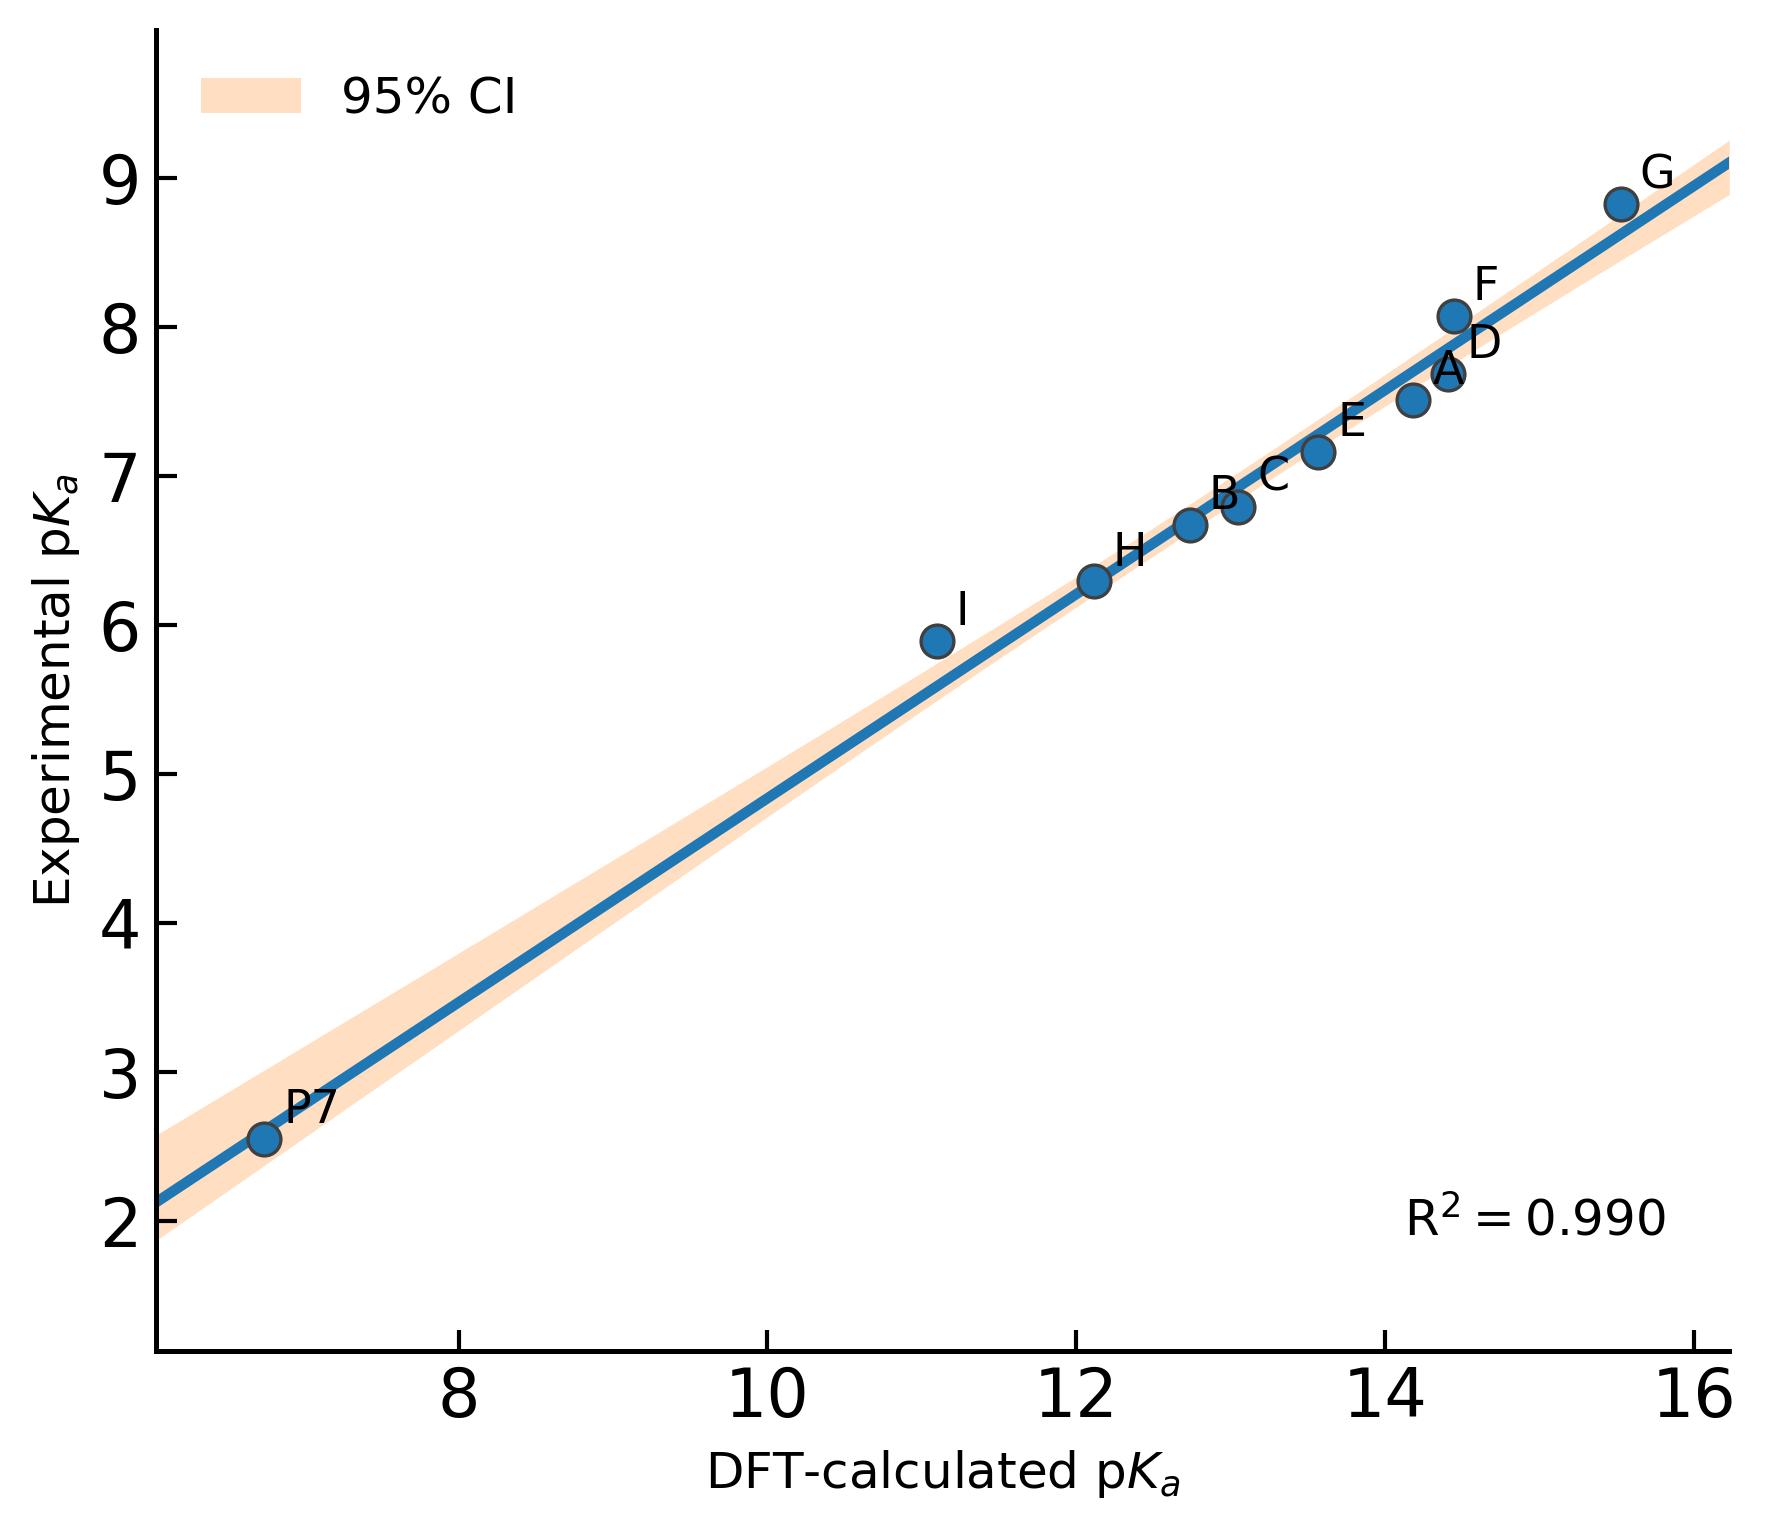

Saved figure to: pka_regression_calibration.png


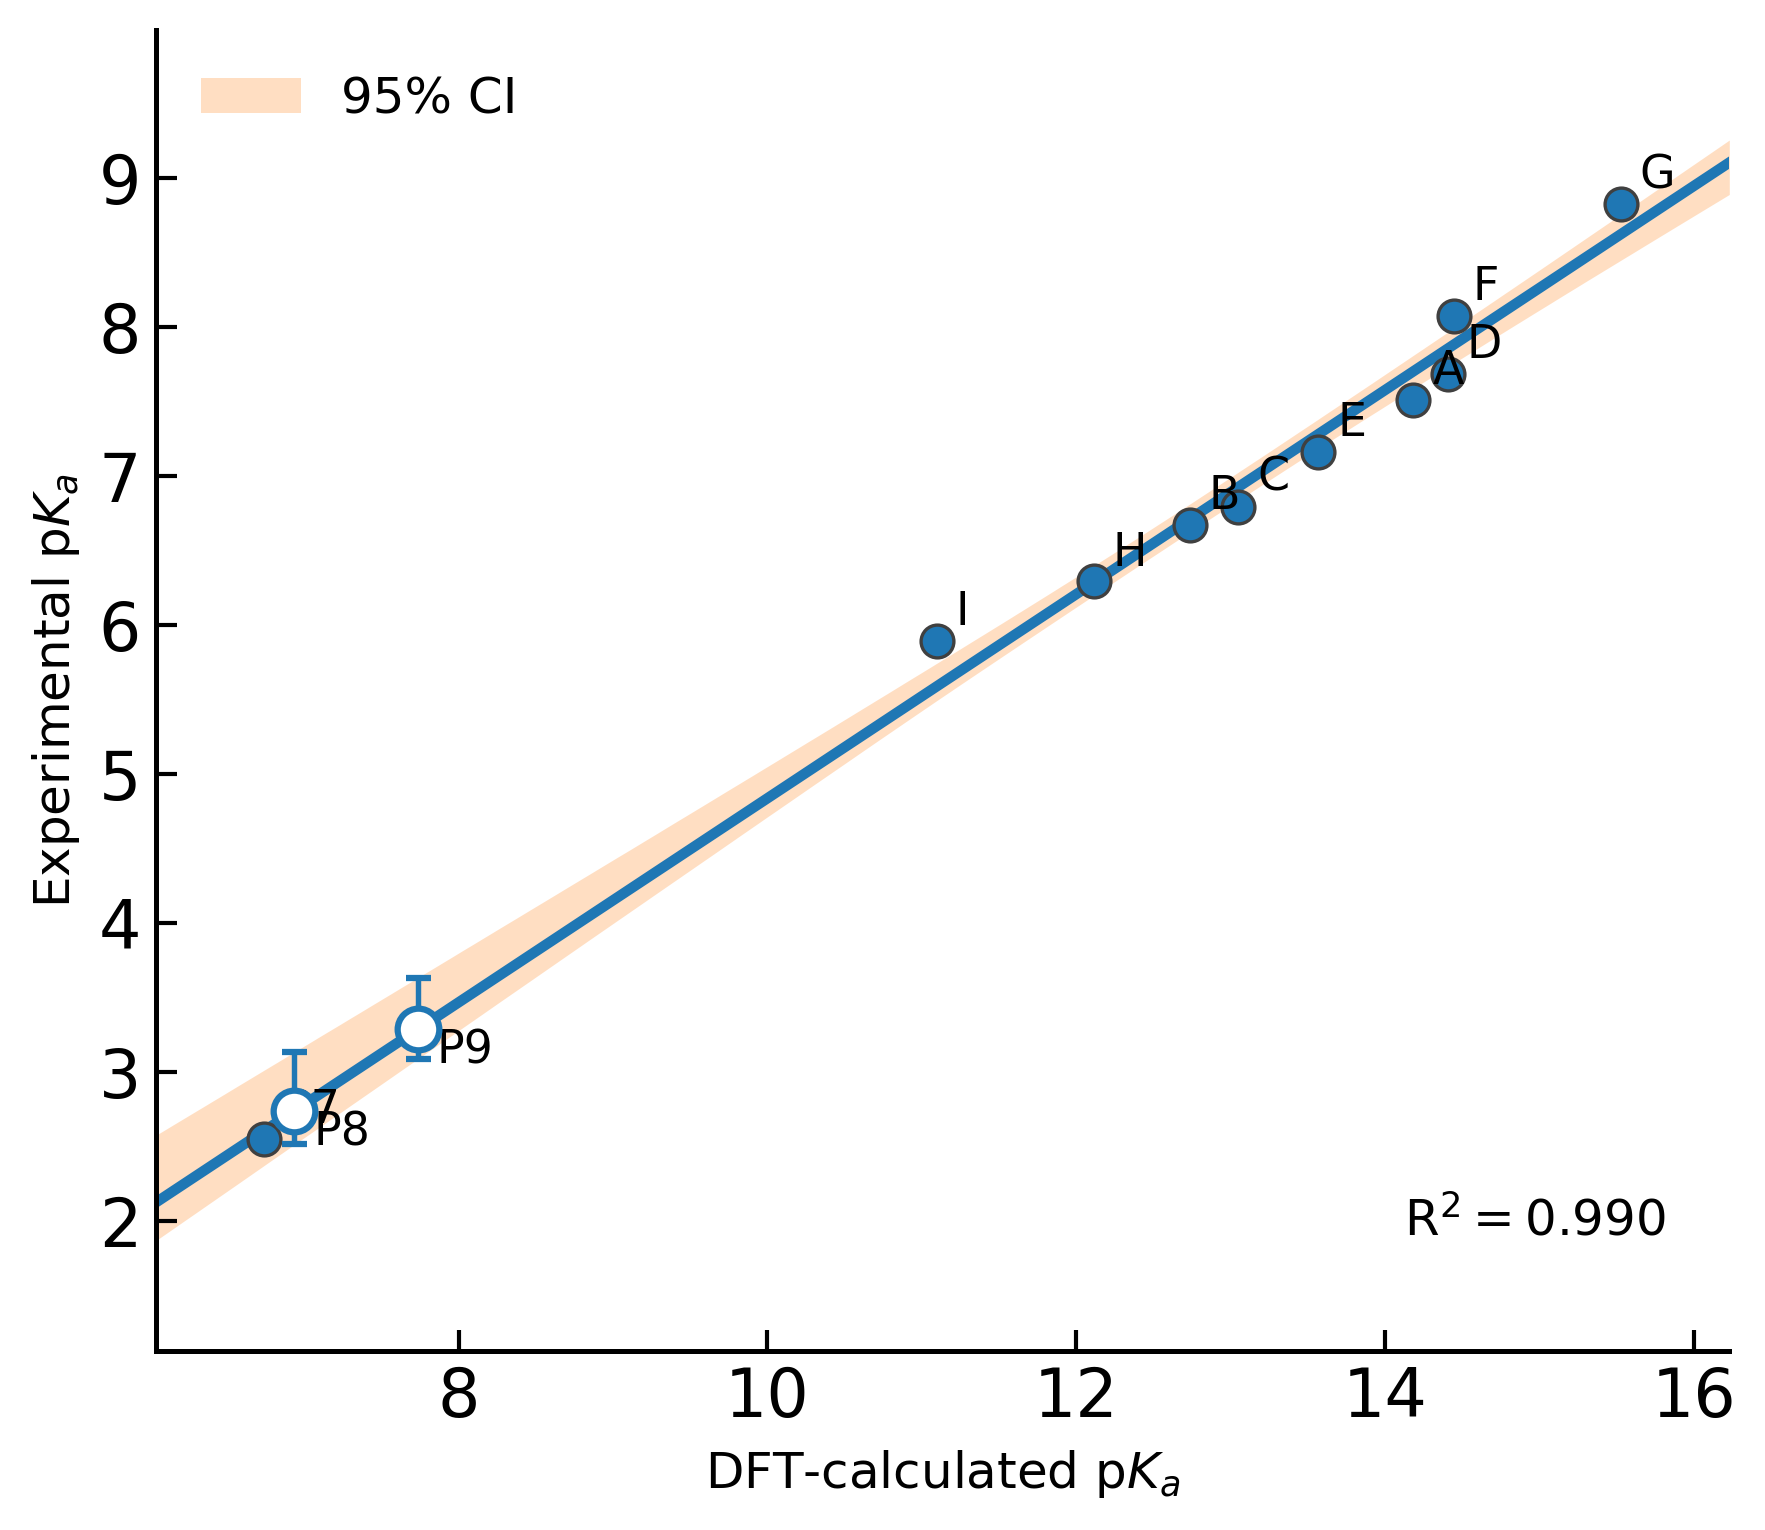

Saved figure to: pka_regression_with_predictions.png


In [25]:
# Plotting of the data.
def annotate_points(ax, x, y, labels, x_offset_fraction=0.012, y_offset_fraction=0.012):
    """Add compact point labels with a small data-coordinate offset."""
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    dx = x_offset_fraction * (xlim[1] - xlim[0])
    dy = y_offset_fraction * (ylim[1] - ylim[0])
    for xi, yi, label in zip(x, y, labels):
        ax.text(xi + dx, yi + dy, str(label), fontsize=11)


def make_pka_plot(include_predictions=False, output_path=PLOT_CALIBRATION_PATH):
    fig, ax = plt.subplots(figsize=(6.0, 5.2), dpi=300)

    # 95% confidence band and fitted line
    ax.fill_between(x_grid, y_grid_low, y_grid_high, color="tab:orange", alpha=0.25, linewidth=0, label="95% CI")
    ax.plot(x_grid, y_grid_center, color="tab:blue", linewidth=2.5)

    # Calibration data
    ax.scatter(x_cal, y_cal, s=62, color="tab:blue", edgecolor="0.25", linewidth=0.8, zorder=3)

    # Optional predicted compounds
    if include_predictions and not predictions.empty:
        x_unknown = predictions[DFT_COL].to_numpy(dtype=float)
        y_unknown = predictions["predicted_pka_exp"].to_numpy(dtype=float)
        yerr_lower = y_unknown - predictions["ci95_lower"].to_numpy(dtype=float)
        yerr_upper = predictions["ci95_upper"].to_numpy(dtype=float) - y_unknown
        ax.errorbar(
            x_unknown,
            y_unknown,
            yerr=[yerr_lower, yerr_upper],
            fmt="o",
            markersize=10,
            color="tab:blue",
            markerfacecolor="white",
            markeredgecolor="tab:blue",
            markeredgewidth=1.5,
            ecolor="tab:blue",
            elinewidth=1.3,
            capsize=3,
            zorder=4,
        )

    ax.set_xlabel(r"DFT-calculated p$K_a$", fontsize=12)
    ax.set_ylabel(r"Experimental p$K_a$", fontsize=12)

    # Axis limits include calibration, fit band, and optional predicted compounds.
    y_values_for_limits = [y_cal, y_grid_low, y_grid_high]
    if include_predictions and not predictions.empty:
        y_values_for_limits.extend([
            predictions["ci95_lower"].to_numpy(dtype=float),
            predictions["ci95_upper"].to_numpy(dtype=float),
        ])
    y_all = np.concatenate(y_values_for_limits)
    y_margin = 0.10 * (np.nanmax(y_all) - np.nanmin(y_all))
    ax.set_xlim(x_grid.min(), x_grid.max())
    ax.set_ylim(np.nanmin(y_all) - y_margin, np.nanmax(y_all) + y_margin)

    # Labels after limits are fixed, so offsets are stable.
    annotate_points(ax, x_cal, y_cal, calibration_df[COMPOUND_COL])
    if include_predictions and not predictions.empty:
        annotate_points(
            ax,
            predictions[DFT_COL].to_numpy(dtype=float),
            predictions["predicted_pka_exp"].to_numpy(dtype=float),
            predictions[COMPOUND_COL],
            x_offset_fraction=0.012,
            y_offset_fraction=-0.026,
        )

    ax.text(
        0.96,
        0.08,
        rf"R$^2 = {r2:.3f}$",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=12,
    )

    ax.legend(frameon=False, loc="upper left", fontsize=12)
    ax.tick_params(axis="both", labelsize=16, direction="in", length=5, width=1.0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.2)
    ax.spines["bottom"].set_linewidth(1.2)
    ax.grid(False)

    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved figure to: {output_path}")

make_pka_plot(include_predictions=False, output_path=PLOT_CALIBRATION_PATH)
make_pka_plot(include_predictions=True, output_path=PLOT_WITH_PREDICTIONS_PATH)
